# Model Calibration and Threshold Optimization
## Healthcare 1C — Issue #20

This notebook evaluates the predicted risk probabilities from
the optimized logistic regression models.

Objectives:
1. Evaluate probability calibration.
2. Compare probability thresholds for identifying high-risk patients.
3. Calculate decile lift for the highest-risk 10% of patients.
4. Compare Baseline A and Baseline B.

In [47]:
import json
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.calibration import calibration_curve
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_predict
)
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    balanced_accuracy_score,
    average_precision_score,
    brier_score_loss
)

ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "models" / "README.md").exists()
)

MODEL_DIR = ROOT / "models"
DATA_DIR = ROOT / "processed datasets"
OUTPUT_DIR = ROOT / "outputs" / "issue_20"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


In [48]:

X = pd.read_csv(DATA_DIR / "X_processed.csv", index_col=0)
y = pd.read_csv(DATA_DIR / "y_processed.csv", index_col=0).iloc[:, 0]

assert X.index.equals(y.index), "Feature/target indexes differ"
assert len(X) == 439887
assert X.shape[1] == 51
assert y.nunique() == 2
assert np.isfinite(X.to_numpy()).all()

print("Features:", X.shape)
print("Targets:", y.shape)
print("Outcome counts:")
print(y.value_counts())


Features: (439887, 51)
Targets: (439887,)
Outcome counts:
adverse_365
0    422300
1     17587
Name: count, dtype: int64


In [49]:

models = {}
metadata_by_baseline = {}

for baseline in ["a", "b"]:
    prefix = f"logistic_regression_baseline_{baseline}"

    with (MODEL_DIR / f"{prefix}_metadata.json").open() as file:
        meta = json.load(file)

    with (MODEL_DIR / f"{prefix}_best.pkl").open("rb") as file:
        pipeline = pickle.load(file)

    models[baseline] = pipeline
    metadata_by_baseline[baseline] = meta

    print(
        f"Baseline {baseline.upper()}: "
        f"{len(meta['feature_columns'])} features"
    )


Baseline A: 30 features
Baseline B: 51 features


In [50]:

meta_a = metadata_by_baseline["a"]
meta_b = metadata_by_baseline["b"]

assert meta_a["random_state"] == meta_b["random_state"]
assert meta_a["test_size"] == meta_b["test_size"]
assert meta_a["positive_class"] == meta_b["positive_class"]

positive_class = meta_a["positive_class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=meta_a["test_size"],
    random_state=meta_a["random_state"],
    stratify=y
)

y_train_binary = (y_train == positive_class).astype(int)
y_test_binary = (y_test == positive_class).astype(int)

assert len(X_test) == meta_a["test_rows"]
assert len(X_train) == meta_a["training_rows"]

print("Training records:", len(X_train))
print("Test records:", len(X_test))
print("Test adverse outcomes:", y_test_binary.sum())


Training records: 351909
Test records: 87978
Test adverse outcomes: 3517


In [51]:

test_probabilities = {}

for baseline in ["a", "b"]:
    model = models[baseline]
    meta = metadata_by_baseline[baseline]

    features = X_test.loc[:, meta["feature_columns"]]
    positive_index = list(model.classes_).index(positive_class)

    probabilities = model.predict_proba(features)[:, positive_index]
    test_probabilities[baseline] = probabilities

    assert np.isfinite(probabilities).all()
    assert ((probabilities >= 0) & (probabilities <= 1)).all()

    print(
        f"Baseline {baseline.upper()}",
        "Average precision:",
        round(average_precision_score(y_test_binary, probabilities), 6)
    )
    print("Saved test AP:", meta["test_metrics"].get("average_precision"))


Baseline A Average precision: 0.08093
Saved test AP: 0.08092974013391824
Baseline B Average precision: 0.08546
Saved test AP: 0.0854598877855384


Baseline A Brier score: 0.037726
Baseline B Brier score: 0.037658


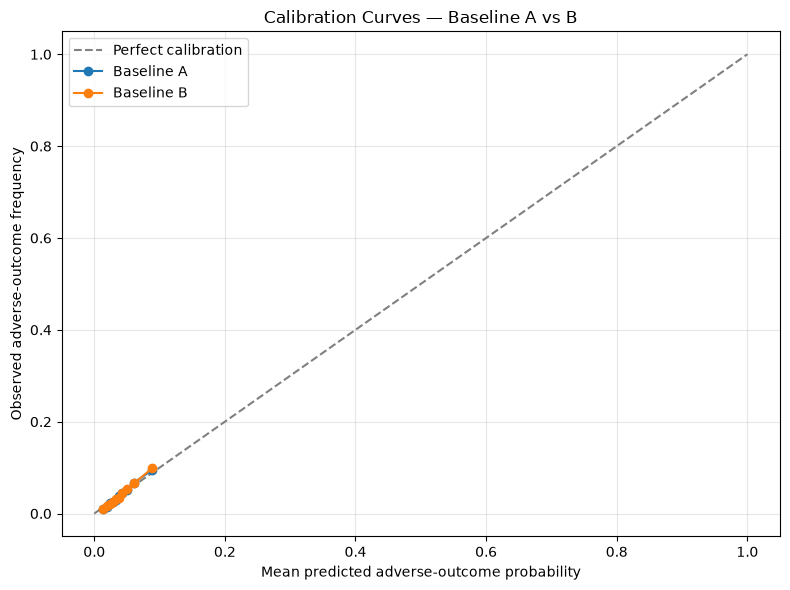

In [52]:

plt.figure(figsize=(8, 6))

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect calibration"
)

for baseline in ["a", "b"]:
    probabilities = test_probabilities[baseline]

    observed, predicted = calibration_curve(
        y_test_binary,
        probabilities,
        n_bins=10,
        strategy="quantile"
    )

    plt.plot(
        predicted,
        observed,
        marker="o",
        label=f"Baseline {baseline.upper()}"
    )

    print(
        f"Baseline {baseline.upper()} Brier score:",
        round(brier_score_loss(y_test_binary, probabilities), 6)
    )

plt.xlabel("Mean predicted adverse-outcome probability")
plt.ylabel("Observed adverse-outcome frequency")
plt.title("Calibration Curves — Baseline A vs B")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "calibration_curves.png", dpi=200)
plt.show()


In [53]:

cv_probabilities = {}

for baseline in ["a", "b"]:
    meta = metadata_by_baseline[baseline]
    model = models[baseline]

    cv = StratifiedKFold(
        n_splits=meta["cv_folds"],
        shuffle=True,
        random_state=meta["random_state"]
    )

    train_features = X_train.loc[:, meta["feature_columns"]]

    out_of_fold = cross_val_predict(
        model,
        train_features,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=1
    )

    positive_index = list(model.classes_).index(positive_class)
    cv_probabilities[baseline] = out_of_fold[:, positive_index]

    print(f"Baseline {baseline.upper()} CV predictions ready")


Baseline A CV predictions ready
Baseline B CV predictions ready


In [54]:

thresholds = np.round(np.arange(0.01, 0.76, 0.01), 2)

def evaluate_thresholds(y_true, probabilities, thresholds):
    rows = []

    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true, predictions, labels=[0, 1]
        ).ravel()

        rows.append({
            "threshold": threshold,
            "recall": recall_score(y_true, predictions, zero_division=0),
            "precision": precision_score(y_true, predictions, zero_division=0),
            "f1": f1_score(y_true, predictions, zero_division=0),
            "accuracy": accuracy_score(y_true, predictions),
            "balanced_accuracy": balanced_accuracy_score(y_true, predictions),
            "false_positive_rate": fp / (fp + tn),
            "flagged": int(predictions.sum()),
            "true_positives": int(tp),
            "false_positives": int(fp),
            "false_negatives": int(fn)
        })

    return pd.DataFrame(rows)

cv_results = {}

for baseline in ["a", "b"]:
    cv_results[baseline] = evaluate_thresholds(
        y_train_binary,
        cv_probabilities[baseline],
        thresholds
    )

    print(f"\nBaseline {baseline.upper()}")
    print(
        cv_results[baseline].loc[
            cv_results[baseline]["threshold"].isin([0.05, 0.10, 0.50, 0.75]),
            ["threshold", "recall", "precision", "f1",
             "false_positive_rate", "flagged"]
        ].to_string(index=False)
    )



Baseline A
 threshold   recall  precision       f1  false_positive_rate  flagged
      0.05 0.465387   0.075595 0.130063             0.237012    86620
      0.10 0.058564   0.131231 0.080987             0.016147     6279
      0.50 0.000000   0.000000 0.000000             0.000000        0
      0.75 0.000000   0.000000 0.000000             0.000000        0

Baseline B
 threshold   recall  precision       f1  false_positive_rate  flagged
      0.05 0.475622   0.077341 0.133047             0.236308    86526
      0.10 0.060697   0.134024 0.083553             0.016333     6372
      0.50 0.000000   0.000000 0.000000             0.000000        0
      0.75 0.000000   0.000000 0.000000             0.000000        0


In [55]:

selected_thresholds = {}

for baseline in ["a", "b"]:
    results = cv_results[baseline]

    best_row = results.loc[results["f1"].idxmax()]
    selected_thresholds[baseline] = float(best_row["threshold"])

    print(f"\nBaseline {baseline.upper()}")
    print("Selected threshold:", selected_thresholds[baseline])
    print("CV F1:", round(best_row["f1"], 4))
    print("CV recall:", round(best_row["recall"], 4))
    print("CV precision:", round(best_row["precision"], 4))



Baseline A
Selected threshold: 0.06
CV F1: 0.1372
CV recall: 0.3205
CV precision: 0.0873

Baseline B
Selected threshold: 0.07
CV F1: 0.1419
CV recall: 0.2264
CV precision: 0.1033


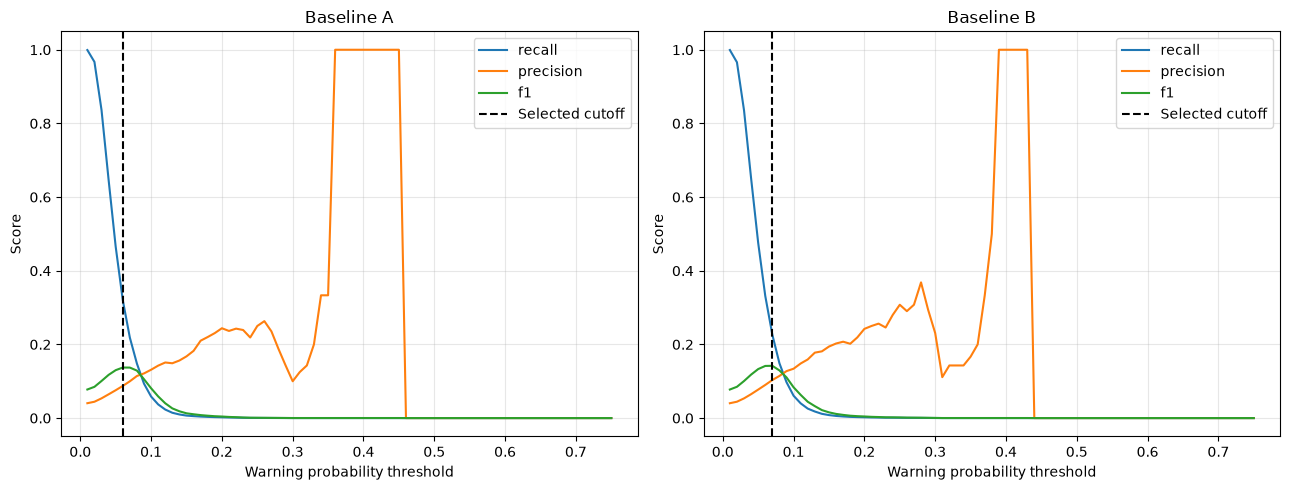

In [56]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, baseline in zip(axes, ["a", "b"]):
    results = cv_results[baseline]

    for metric in ["recall", "precision", "f1"]:
        ax.plot(results["threshold"], results[metric], label=metric)

    ax.axvline(
        selected_thresholds[baseline],
        linestyle="--",
        color="black",
        label="Selected cutoff"
    )

    ax.set_title(f"Baseline {baseline.upper()}")
    ax.set_xlabel("Warning probability threshold")
    ax.set_ylabel("Score")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "threshold_comparison.png", dpi=200)
plt.show()


In [57]:

test_results = []

for baseline in ["a", "b"]:
    threshold = selected_thresholds[baseline]
    probabilities = test_probabilities[baseline]

    for label, cutoff in [("Default 0.50", 0.50), ("Selected", threshold)]:
        predictions = (probabilities >= cutoff).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_test_binary, predictions, labels=[0, 1]
        ).ravel()

        test_results.append({
            "baseline": baseline.upper(),
            "cutoff_type": label,
            "threshold": cutoff,
            "recall": recall_score(y_test_binary, predictions, zero_division=0),
            "precision": precision_score(y_test_binary, predictions, zero_division=0),
            "f1": f1_score(y_test_binary, predictions, zero_division=0),
            "accuracy": accuracy_score(y_test_binary, predictions),
            "true_positives": tp,
            "false_positives": fp,
            "false_negatives": fn,
            "true_negatives": tn
        })

test_results_df = pd.DataFrame(test_results)
display(test_results_df)


,baseline,cutoff_type,threshold,recall,precision,f1,accuracy,true_positives,false_positives,false_negatives,true_negatives
0,A,Default 0.50,0.50,0.000000,0.000000,0.000000,0.960024,0,0,3517,84461
1,A,Selected,0.06,0.328689,0.086006,0.136337,0.833527,1156,12285,2361,72176
2,B,Default 0.50,0.50,0.000000,0.000000,0.000000,0.960024,0,0,3517,84461
3,B,Selected,0.07,0.237418,0.102028,0.142723,0.885983,835,7349,2682,77112


In [58]:

def calculate_decile_lift(y_true, probabilities):
    y_array = np.asarray(y_true)
    probabilities = np.asarray(probabilities)

    top_count = int(np.ceil(len(probabilities) * 0.10))
    top_indices = np.argsort(-probabilities, kind="stable")[:top_count]

    overall_rate = y_array.mean()
    top_rate = y_array[top_indices].mean()
    lift = top_rate / overall_rate

    capture_rate = y_array[top_indices].sum() / y_array.sum()

    return {
        "top_10_percent_records": top_count,
        "overall_event_rate": overall_rate,
        "top_decile_event_rate": top_rate,
        "decile_lift": lift,
        "event_capture_rate": capture_rate
    }

lift_results = {}

for baseline in ["a", "b"]:
    lift_results[baseline] = calculate_decile_lift(
        y_test_binary,
        test_probabilities[baseline]
    )

lift_df = pd.DataFrame(lift_results).T
display(lift_df)


,top_10_percent_records,overall_event_rate,top_decile_event_rate,decile_lift,event_capture_rate
a,8798.0,0.039976,0.094794,2.371285,0.237134
b,8798.0,0.039976,0.099000,2.476486,0.247654


In [59]:

OUTPUT_DIR = ROOT / "outputs" / "issue_20"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for baseline in ["a", "b"]:
    cv_results[baseline].to_csv(
        OUTPUT_DIR / f"baseline_{baseline}_threshold_cv.csv",
        index=False
    )

test_results_df.to_csv(
    OUTPUT_DIR / "selected_threshold_test_results.csv",
    index=False
)

lift_df.to_csv(
    OUTPUT_DIR / "decile_lift_results.csv"
)

print("Results saved to:", OUTPUT_DIR)


Results saved to: /Users/daniellenyame/Healthcare-1C-predicting-organ-transplant-waitlist-outcomes-and-optimizing-allocation/outputs/issue_20


## Findings and Interpretation

This analysis compared the calibration and warning thresholds of two logistic regression models predicting adverse organ transplant waitlist outcomes.

**Calibration:** Both models were evaluated using calibration curves and Brier scores to examine how closely predicted probabilities matched observed outcomes.

**Threshold selection:** Using cross-validation predictions from the training data, the F1-based analysis selected a 6% warning threshold for Baseline A and a 7% threshold for Baseline B.

**Model comparison:** Baseline B achieved a slightly higher cross-validation F1 score, while Baseline A achieved higher recall at its selected threshold.

**Top-decile lift:** The analysis also evaluated how effectively each model concentrated adverse outcomes among the 10% of patients assigned the highest predicted risk.

**Limitations:** These thresholds are exploratory and have not been clinically validated. Future work should consider the consequences of false positives and missed adverse outcomes, potential data leakage, and fairness across patient populations.